# 25. Как гнётся лента из пяти гауссиан

[Программа курса](../../README_ru.md)

Пять цветных пятен лежат на одной линии. Если сохранить по пять гауссиан для каждого кадра, получится целая стопка почти одинаковых лент. А если оставить одну ленту и карту, на которой записано, насколько она изгибается? Тогда по карте можно нарисовать и момент между двумя кадрами.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "deformation.py").is_file())
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import deformation as motion
import deformation_demos as demos
np.set_printoptions(precision=5, suppress=True)

## Одна сцена до и после сгиба

У левого синего пятна координата по горизонтали равна −0.8 м. У оранжевого на другом конце она равна 0.8 м. По вертикали все центры лежат на нуле, а в глубину — на 4 м. Эти координаты в исходном положении называются **каноническими**. Камера смотрит вперёд, ось высоты картинки направлена вниз, поэтому для подъёма ленты надо *вычесть* расстояние из координаты $y$.

На первой картинке всегда видна исходная лента. На второй смещение каждого пятна берётся с общей карты. При смене ракурса обе картинки поворачиваются одновременно. Точка на карте остаётся на месте, пока время и номер пятна прежние.

In [2]:
display(demos.lab(25, "ru"))

## Как прочитать число между четырьмя узлами

У карты две оси. Слева направо меняется положение вдоль ленты, снизу вверх идёт время. Чтобы не смешивать метры с номерами ячеек, переведём горизонтальную координату из отрезка от −1 до 1 м в долю от 0 до 1. Сначала прибавим 1 м, чтобы левый край стал нулём. Затем разделим на длину отрезка, 2 м. Для оранжевого центра получается $u=(0.8+1)/2=0.9$. Это девять десятых пути от левого края к правому. По времени запись длится одну секунду. В момент $t=0.5$ с доля времени $v=t/(1\,\mathrm{s})$ равна 0.5.

| Доля времени | Левый узел, $u=0$ | Правый узел, $u=1$ |
|---|---:|---:|
| Начало, 0 | 0 | 0 |
| Конец, 1 | 0 | 1 |

В каждом узле записано безразмерное число. Английское слово *feature* в этой задаче означает именно такое число. Сначала идём вдоль нижней строки. До правого края осталось $1-0.9=0.1$ пути. Поэтому левое значение получает вес 0.1, правое — 0.9. Получится $0.1\cdot0+0.9\cdot0=0$. В верхней строке те же веса дают $0.1\cdot0+0.9\cdot1=0.9$. Момент 0.5 лежит ровно между строками, берём половину от каждой: $0.5\cdot0+0.5\cdot0.9=0.45$.

Этот расчёт называется **билинейной интерполяцией**. Буква $F$ ниже обозначает прочитанное число. Индексы в $g_{ij}$ обозначают сначала столбец $i$, затем строку $j$, оба от нуля до единицы. Веса внутри скобок отвечают за движение по горизонтали. Снаружи скобок — за время.

$$
F(u,v)=(1-v)\big[(1-u)g_{00}+u g_{10}\big]+v\big[(1-u)g_{01}+u g_{11}\big].
$$

При $u=0.9$ и $v=0.5$ четыре веса равны 0.05, 0.45, 0.05 и 0.45. В сумме получается единица. Если в каждом углу записать одно и то же число, после смешивания оно останется тем же.

In [3]:
x = motion.ribbon()["splats"][-1]["center"][0]
u = (x + 1) / 2
print("u =", u, " F =", motion.field_value(u, .5))

u = 0.9  F = 0.45


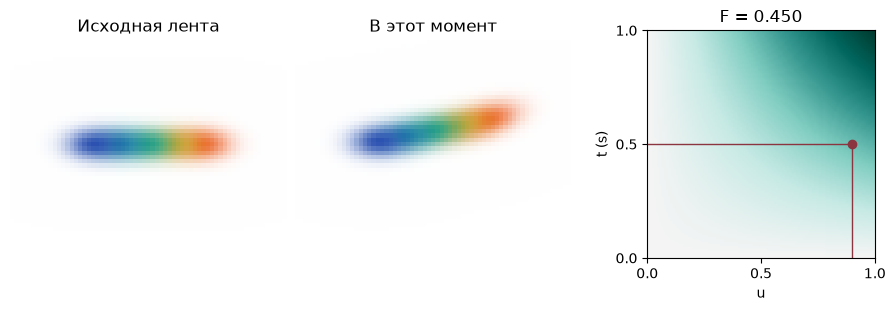

In [4]:
fig = demos.field_figure(lang="ru")
plt.show()

## Из числа получается движение

Число 0.45 пока ничего не говорит о метрах. Назначим значение 1 полному подъёму на 0.8 м. Тогда $\Delta y=-0.8\cdot0.45=-0.36$ м. Новый центр равен $(0.8,-0.36,4)$ м. Повороту назначим −35° при единичном значении. Получится $-35\cdot0.45=-15.75$°. Для поворота вокруг оси глубины в четырёх числах из урока 12 остаются $q=(\cos(\theta/2),0,0,\sin(\theta/2))$. Перед вычислением синуса и косинуса градусы переводятся в радианы множителем $\pi/180$. Уменьшение угла вдвое даёт −7.875°, или примерно −0.1374 радиана. Первое число кватерниона близко к 0.991, последнее — к −0.137.

Длинный масштаб пятна в покое равен 0.27 м. Пусть единичное значение карты удлиняет его на 30 %. Тогда множитель $1+0.3\cdot0.45=1.135$, новый масштаб $0.27\cdot1.135=0.30645$ м. Цвет и непрозрачность те же. Эти три правила образуют наш **декодер**: он превращает одно число карты в изменение центра, поворота и размера. Каждое изменение считается от одной и той же исходной ленты. Если остановить время, повторный расчёт оставит пятно на прежнем месте.

In [5]:
tip = motion.field_scene(.5)["splats"][-1]
for name in ("center", "rotation", "scales"):
    print(name, np.round(tip[name], 5))

center [ 0.8  -0.36  4.  ]
rotation [ 0.99057  0.       0.      -0.13701]
scales [0.30645 0.15    0.12   ]


## Что добавляется в работе Wu и соавторов

У нашей карты есть неудобное свойство. Два пятна с одинаковым $x$ и разной глубиной всегда получают один и тот же сгиб. В реализации 4D-GS запрос состоит из четырёх координат $(x,y,z,t)$. Из них получаются шесть пар: $xy$, $xz$, $yz$, $xt$, $yt$, $zt$. Для каждой пары есть своя плоскость с обучаемыми значениями. Например, точки на одной вертикали могут совпасть на плоскости $xt$ и разойтись на плоскости $zt$. В коде авторов значения интерполируются, затем перемножаются покомпонентно в пределах одного разрешения. Если в одном канале шесть значений равны $1,1,1,0.45,1,0.8$, произведение равно $0.36$. Результаты разных разрешений соединяются в один список. [Интерполяция в реализации авторов](https://github.com/hustvl/4DGaussians/blob/master/scene/hexplane.py)

Дальше небольшая нейросеть предсказывает поправки к параметрам канонических гауссиан. При обучении рендер сравнивается с наблюдаемыми изображениями. Наши четыре узла и три заранее заданных правила позволяют проследить путь одного числа вплоть до экрана. В полной модели значения узлов, параметры декодера и исходные гауссианы находятся по кадрам. [Wu и соавторы, 4D Gaussian Splatting, CVPR 2024](https://guanjunwu.github.io/4dgs/)

## Сгиб в обратную сторону

Что произойдёт в момент 0.5 с, если в правом верхнем узле вместо 1 окажется −1? Почему при смене камеры ответ для центра прежний, хотя изображение меняется?

<details>
<summary>Разбор</summary>

В верхней строке получится −0.9, в нижней ноль. Посередине по времени значение карты равно −0.45. Смещение по вертикали $-0.8\cdot(-0.45)=+0.36$ м направлено вниз. Длина пятна равна $0.27(1-0.135)=0.23355$ м. Поворот меняет знак и становится +15.75°. В этих действиях участвовали только исходный центр, время и узлы. Камера впервые понадобится на следующем шаге, когда новый эллипсоид будет спроецирован на экран.

</details>

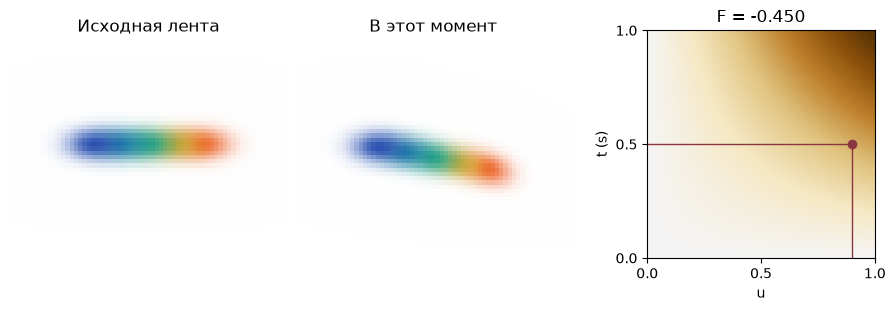

In [6]:
fig = demos.field_figure(corner=-1, lang="ru")
plt.show()